# Job Matching, Historical Hiring Bias, and Fairlearn

**A guided investigation | 2 hours | Python 3.12 | CPU laptop**

> We will trace two problems in a hiring workflow: past decisions can carry bias into a model, and hiring outcomes are observed only for shortlisted applicants. We will use Fairlearn to measure group differences, then decide what those numbers can and cannot tell us.

The job descriptions and CVs in this workshop are drawn from the existing job-matching case; all CV profiles are fictional. Fairness attributes and historical decisions are separately simulated. This is not evidence about real applicants or Ethiopian hiring.

Run from the top. Work in pairs. At every **PAUSE**, write a prediction before running the next cell. The helper contains the algorithm implementations; the editable choices remain visible below.

**Learning path:** compare three rankings → perturb parameters → inspect synthetic history → audit with Fairlearn → make a bounded recommendation.


## Set up the investigation

The source bundle contains 14 available public-sector job descriptions across health, agriculture, finance, aviation, engineering, infrastructure, and IT, at entry, mid, senior, and management levels. They are source-faithful paraphrases, not verified current vacancies.

The corresponding 699 candidate profiles are fictional. Each has a stable ID, qualifications, skills, experience years, and a longer CV narrative with education and work history. The pool has 49 or 50 profiles per vacancy. We use `JD-01` for the first comparison; change `JOB_ID` after the opening exercise.

The synthetic recruitment history stays closed until Problem 3. It was generated separately from the fictional CV text and is not actual hiring data.


In [1]:
from pathlib import Path
import sys
from dotenv import load_dotenv
import pandas as pd
import matplotlib.pyplot as plt

WORKSHOP_DIR = next(p for p in [Path.cwd(), Path.cwd() / 'job-matching-fairness', *Path.cwd().parents]
                    if (p / 'job_matching_helpers.py').exists())
load_dotenv(WORKSHOP_DIR.parent / ".env", override=False)
sys.path.insert(0, str(WORKSHOP_DIR))
from job_matching_helpers import (
    load_jobs, load_candidates, load_history,
    match_tfidf, match_bm25, match_llm, select_top_k,
    compare_rankings, prepare_group_selection_data,
    fairness_metrics, group_agreement_metrics,
    fairness_metrics_with_reference_labels,
    plot_rankings, plot_group_rates,
)

JOB_ID = 'JD-01'
jobs = load_jobs()
job_row = jobs.loc[jobs.job_id == JOB_ID].iloc[0]
job_description = job_row.text
candidates = load_candidates(JOB_ID)
print(f"Vacancies in this dataset: {len(jobs)}")
print('Vacancies by sector:')
display(jobs.groupby('sector').size().rename('vacancies').to_frame())
print(f"Opening pool: {JOB_ID} with {len(candidates)} fictional CV profiles")
print('Each profile includes qualifications, skill keywords, experience years, and a longer education/work-history narrative.')
print('Individual CV text is not printed in this notebook.')
print('Synthetic historical hiring data is introduced in Problem 3.')


Vacancies in this dataset: 14
Vacancies by sector:


,vacancies
sector,
Agriculture / Procurement,1
Agriculture / Supply Chain,1
Aviation / Supply Chain,1
Construction / Procurement,1
Energy / Procurement,1
Finance / Accounting,1
Finance / Public Administration,1
Financial Regulation / Strategy,1
Health / Biostatistics,1


Opening pool: JD-01 with 50 fictional CV profiles
Each profile includes qualifications, skill keywords, experience years, and a longer education/work-history narrative.
Individual CV text is not printed in this notebook.
Synthetic historical hiring data is introduced in Problem 3.


### Problem 1 — Do different algorithms recommend the same candidates?

**Problem.** A recruitment team needs a first-pass ranking. The three methods turn the same job description and CV text into different kinds of relevance score. None verifies job performance.

### How a text ranking becomes a shortlist

A **ranking** orders candidates from the method's highest score to its lowest. A **Top-K shortlist** takes the first K rows after that ordering. The three methods below use different scoring rules, so a score of `0.6` from one method does not mean the same thing as `0.6` from another.

#### TF-IDF: weighted word overlap

1. The method splits the job description and every CV into words and, if configured, short phrases called *n-grams*.
2. It gives each term a weight: terms repeated in one document matter more, while terms appearing in many of the fitted JD/CV texts carry less information. This is **term frequency–inverse document frequency**.
3. It represents the job and each CV as weighted vectors, then calculates **cosine similarity**. A CV with more high-weight terms in common with the JD gets a higher score.
4. It sorts candidates by cosine score, highest first. With the default settings the score is between 0 and 1. Exact word overlap matters; a synonym the JD does not use may contribute nothing.

#### BM25: query-term retrieval with length adjustment

1. The method treats the JD's distinct words as query terms and counts how often each appears in each CV.
2. Rare query terms in the applicant pool carry more weight than common terms. Repeating a term helps, but with **diminishing returns**: the tenth mention adds less than the first few.
3. It adjusts for CV length, so a long CV does not win just by containing more words. The `b` setting controls the strength of this length adjustment; `k1` controls how quickly repeated mentions saturate.
4. It adds the weighted term contributions and sorts by total BM25 score, highest first. BM25 is still lexical: it does not understand a synonym unless its words overlap the query.

#### LLM matching: rubric-based evidence

1. The model receives the JD, a job-related scoring rubric, and one CV divided into text sections.
2. For each rubric requirement it returns a status such as supported, explicitly not met, or unknown, with a quote and section location when it claims evidence.
3. The helper checks that cited quotes really occur in the supplied CV section. In live mode it calculates a weighted evidence-coverage score; candidates are ordered by that score. This can respond to context and equivalent wording, but a model can still miss evidence or misread it.
4. The offline ranking here is a **saved prior Top-5 result**, labelled cached. It is not a fresh model call and has no results below rank 5.

**Ties and ranks.** Two candidates can receive the same score. The TF-IDF, BM25, and live LLM helper uses candidate ID to order exact score ties for a reproducible table; the cached LLM list keeps the order saved by the earlier run. A one-place rank difference is not automatically a meaningful quality difference.

**Tiny example.** Suppose the JD asks for Python forecasting and public-health data. One CV says “Python forecasting”; another describes “time-series predictions for a health programme.” TF-IDF and BM25 may favor the first because its words match directly. An LLM rubric may recognize the second as related evidence, or may not. The run lets us inspect what happened; it does not tell us which applicant is more qualified.

### PAUSE & PREDICT — 3 minutes

Write down: Which method will find the most relevant CVs? Will the top five overlap? Could the wording of a CV influence its rank?

### Hands-on Exercise

Review the job metadata and the profile fields described above. Name two job-related qualifications you would look for. Run the three methods, then compare rank position and Top-5 membership. Cached LLM output is a saved prior project result for K=5, not live inference. Do not compare raw scores across methods.


algorithm,BM25,LLM cached Top-5,TF-IDF
rank,,,
1,CV-01-029,CV-01-003,CV-01-001
2,CV-01-012,CV-01-005,CV-01-020
3,CV-01-044,CV-01-007,CV-01-037
4,CV-01-034,CV-01-009,CV-01-007
5,CV-01-018,CV-01-017,CV-01-014


Pairwise shared candidates in Top 5:


,left,right,shared_top_k,k
0,TF-IDF,BM25,0,5
1,TF-IDF,LLM cached Top-5,1,5
2,BM25,LLM cached Top-5,0,5


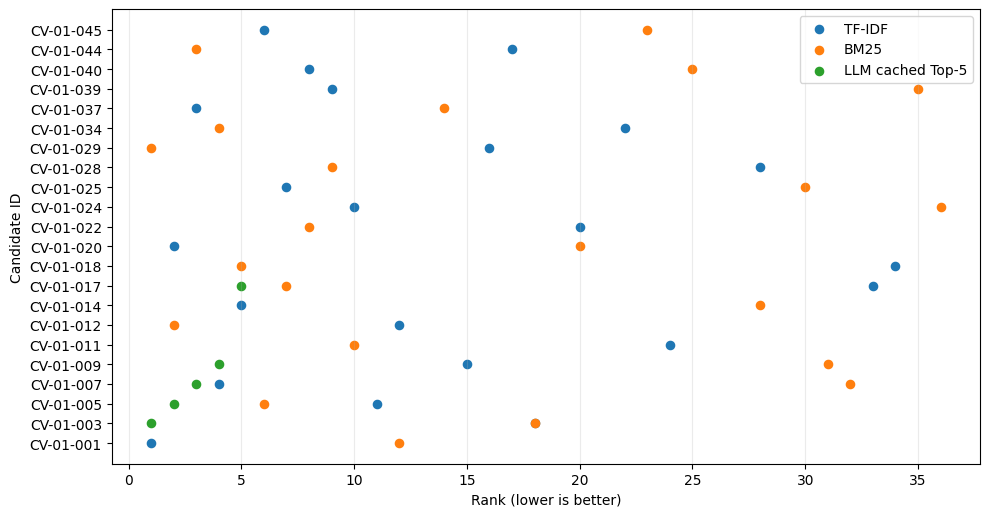

In [2]:
# The settings are intentionally explicit; change these after recording your prediction.
tfidf = match_tfidf(job_description, candidates, ngram_range=(1, 1),
                    max_features=None, min_df=1, max_df=1.0)
bm25 = match_bm25(job_description, candidates, k1=1.5, b=0.75)
llm = match_llm(JOB_ID, job_description, candidates, mode='cached')
rankings = {'TF-IDF': tfidf, 'BM25': bm25, 'LLM cached Top-5': llm}

top_five = pd.concat([
    frame.head(5)[['candidate_id', 'rank', 'score']].assign(algorithm=name)
    for name, frame in rankings.items()
], ignore_index=True)
display(top_five.pivot(index='rank', columns='algorithm', values='candidate_id'))
print('Pairwise shared candidates in Top 5:')
_, overlap = compare_rankings(rankings, k=5)
display(overlap)
fig, ax = plot_rankings(rankings, k=10)
plt.show()

### Observe Results

**How to read the ranking output:** Each column in the rank table is a method; its header names the algorithm. A number is the candidate?s position in that method?s ordered list (`1` is first). `NaN` means the candidate is outside that displayed Top 10. In the overlap table, `shared_top_k` counts how many candidate IDs both methods put in their Top 5. For this run, TF-IDF and cached LLM share 1 of 5 candidates; BM25 shares 0 with either. The plot and overlap describe ranking differences, not which method is more accurate.

Mark the candidates that appear in more than one Top 5. Look at the rank plot: a candidate can be near the top for one method and far lower for another.

### Discussion

- Which candidates changed rank the most? Can you point to CV wording that may explain a lexical match?
- Did the LLM cite job-related evidence in its saved ranking report? A high score alone is not a reason.
- What independent relevance judgments would you need to call any ranking better?

**Key Takeaway:** A matching score measures a method's response to its inputs and settings; it is not a common quality scale or proof of candidate suitability.


### Problem 2 — How do parameters influence recommendations?

**Problem.** Reviewers say a strong candidate is missing from the first shortlist. Before changing the process, isolate which settings change the ranking.

**What the settings change.** Each algorithm produces a score for each CV, then orders candidates by that score. Change one control at a time so you can connect a rank movement to a cause.

| Method and setting | What changes inside the ranking | What to look for |
|---|---|---|
| TF-IDF `ngram_range=(1, 1)` vs `(1, 2)` | Enables two-word phrases as well as single terms. “Data quality” can become a feature of its own. | Do CVs using the same phrases as the JD move up? |
| TF-IDF `max_features` | Keeps only a limited vocabulary, based on term frequency in the fitted text. A term left out cannot contribute to similarity. | Which candidates lose distinctive but less frequent terms? |
| TF-IDF `min_df` / `max_df` | Drops terms below or above a document-frequency threshold. | Are rare skills or common boilerplate being removed? |
| BM25 `k1` | Sets the rate of diminishing returns for repeated query terms. Higher values let repeated mentions keep adding more score for longer. | Do CVs repeating a JD term move relative to CVs mentioning it once? |
| BM25 `b` | Sets the strength of CV-length normalization. Near 0 means little length adjustment; near 1 means stronger adjustment. | Do long CVs move when length matters more? |
| LLM model, prompt, rubric weights | Changes the model's evidence interpretation or which requirements count more in its weighted coverage score. | Does emphasizing one requirement change evidence or the order? The cached list will not change; use live mode for this experiment. |
| Top K | Changes the cut-off after ranking, not the score or underlying order. | Who crosses into or out of the shortlist when K changes? |

**Example of a controlled comparison:** run the default TF-IDF settings, predict what adding two-word phrases will do, change only `ngram_range`, then compare ranks and Top-K overlap. Repeat separately for BM25. The score scales remain method-specific; compare order and shortlist membership, not raw score magnitudes.

### PAUSE & PREDICT — 2 minutes

Choose one setting you expect to have the greatest effect: adding bigrams, capping vocabulary, increasing `k1`, changing `b`, changing K, or editing an LLM requirement weight. Predict which candidate moves and why.

### Hands-on Exercise

Change one parameter at a time. Keep the JD and applicant pool fixed. For TF-IDF try unigram+bigrams and a `max_features` cap. For BM25 vary `k1` and `b`. Change K for the lexical methods. In live mode, edit one LLM rubric weight or job-related prompt instruction; the saved LLM cache does not change when settings change. Temperature is optional and some models may not support it.


In [3]:
tfidf_changed = match_tfidf(job_description, candidates, ngram_range=(1, 2),
                              max_features=4000, min_df=1, max_df=1.0)
bm25_changed = match_bm25(job_description, candidates, k1=0.8, b=0.25)
changed = {'TF-IDF default': tfidf, 'TF-IDF (1,2)': tfidf_changed,
           'BM25 default': bm25, 'BM25 (k1=.8,b=.25)': bm25_changed}
rank_changes = pd.concat([
    frame.head(10)[['candidate_id', 'rank']].assign(configuration=name)
    for name, frame in changed.items()
], ignore_index=True)
display(rank_changes.pivot(index='candidate_id', columns='configuration', values='rank')
        .sort_values('TF-IDF default').head(15))
for k in [3, 5, 10]:
    print(f"\nTop-{k} overlap: TF-IDF default vs changed; BM25 default vs changed")
    _, table = compare_rankings(
        {'TF-IDF default': tfidf, 'TF-IDF changed': tfidf_changed,
         'BM25 default': bm25, 'BM25 changed': bm25_changed}, k=k)
    display(table)

configuration,"BM25 (k1=.8,b=.25)",BM25 default,"TF-IDF (1,2)",TF-IDF default
candidate_id,,,,
CV-01-001,NaN,NaN,4.0,1.0
CV-01-020,NaN,NaN,3.0,2.0
CV-01-037,NaN,NaN,2.0,3.0
CV-01-007,NaN,NaN,1.0,4.0
CV-01-014,NaN,NaN,5.0,5.0
CV-01-045,NaN,NaN,6.0,6.0
CV-01-025,NaN,NaN,10.0,7.0
CV-01-040,NaN,NaN,9.0,8.0
CV-01-039,NaN,NaN,NaN,9.0



Top-3 overlap: TF-IDF default vs changed; BM25 default vs changed


,left,right,shared_top_k,k
0,TF-IDF default,TF-IDF changed,2,3
1,TF-IDF default,BM25 default,0,3
2,TF-IDF default,BM25 changed,0,3
3,TF-IDF changed,BM25 default,0,3
4,TF-IDF changed,BM25 changed,0,3
5,BM25 default,BM25 changed,3,3



Top-5 overlap: TF-IDF default vs changed; BM25 default vs changed


,left,right,shared_top_k,k
0,TF-IDF default,TF-IDF changed,5,5
1,TF-IDF default,BM25 default,0,5
2,TF-IDF default,BM25 changed,0,5
3,TF-IDF changed,BM25 default,0,5
4,TF-IDF changed,BM25 changed,0,5
5,BM25 default,BM25 changed,4,5



Top-10 overlap: TF-IDF default vs changed; BM25 default vs changed


,left,right,shared_top_k,k
0,TF-IDF default,TF-IDF changed,8,10
1,TF-IDF default,BM25 default,0,10
2,TF-IDF default,BM25 changed,0,10
3,TF-IDF changed,BM25 default,0,10
4,TF-IDF changed,BM25 changed,0,10
5,BM25 default,BM25 changed,10,10


### Live LLM: a job-specific evidence rubric

The previous three broad categories gave 49 of 50 applicants a score of 80. This replacement separates JD-01's actual requirements. **Essential requirements** (degree, degree-dependent relevant experience, publication counts) use binary evidence checks. **Technical criteria** use 0 = not demonstrated, 1 = named only, 2 = applied in a concrete responsibility or project. Unknown is distinct from explicit evidence of not meeting a threshold. Stated responsibilities are still self-reported synthetic CV evidence, not independently verified competence.

Python computes **100 ? sum(weight ? evidence_level / max_level) / sum(weights)**. Weights below are illustrative priorities, fixed before running; they are not validated hiring criteria. A high score does not override an unmet essential requirement. The separate essential-requirement column is an LLM evidence flag for review; this teaching ranking does not automatically filter applicants or make an eligibility decision. Later Fairlearn tables audit the score-based Top 5, not an eligibility-filtered recruitment policy.

This cell displays only the algorithm comparison, shortlist overlap and rank chart. Detailed scores, quotations and essential-requirement flags remain available in `llm_live`; equal scores are still ordered by candidate ID. Do not adjust criteria just to produce more distinct scores. This rubric applies only to JD-01; the saved Problem 1 LLM baseline is unchanged.


algorithm,BM25,LLM live,TF-IDF
rank,,,
1,CV-01-029,CV-01-006,CV-01-001
2,CV-01-012,CV-01-001,CV-01-020
3,CV-01-044,CV-01-026,CV-01-037
4,CV-01-034,CV-01-011,CV-01-007
5,CV-01-018,CV-01-017,CV-01-014


,left,right,shared_top_k,k
0,TF-IDF,BM25,0,5
1,TF-IDF,LLM live,1,5
2,BM25,LLM live,0,5


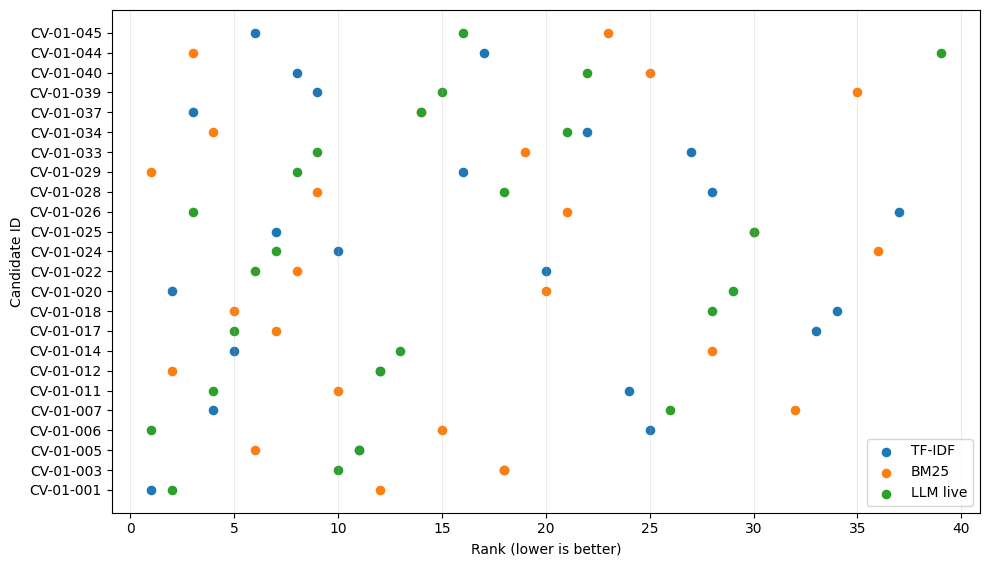

In [4]:
# Optional live LLM experiment. Cached mode above makes the notebook run without a key.
# For live mode, set OPENROUTER_API_KEY in the local .env file or shell; rerun setup after editing .env.
# Use only the fictional CVs supplied with this workshop. Live mode sends CV text to OpenRouter.
RUN_LIVE_LLM = True
LLM_MODEL = 'meta-llama/llama-3.3-70b-instruct'
# This rubric is specific to JD-01; derive a new rubric before changing jobs.
SCORING_PROMPT = (
    'Assess only the supplied JD-01 requirements using the defined evidence levels. '
    'A skill name alone is not evidence of application. Do not invent degrees, years or publications.'
)
EVIDENCE_LEVELS = {
    '0': 'Not demonstrated: distinguish unknown from explicitly_not_met using status.',
    '1': 'The relevant skill or method is explicitly named, but no applied responsibility or project is evidenced.',
    '2': 'A concrete responsibility or project describes applying the relevant skill or method.',
}
BINARY_LEVELS = {'0': 'Not established; distinguish unknown from explicitly_not_met.',
                 '1': 'The stated threshold is explicitly supported by the CV.'}
# Illustrative teaching weights fixed before this run, not validated hiring priorities.
LLM_RUBRIC = [
    {'text': 'A PhD or Masters degree in a quantitative discipline. A Bachelors degree alone does not establish this requirement.',
     'weight': 1, 'max_level': 1, 'essential': True, 'levels': BINARY_LEVELS},
    {'text': 'Relevant experience: at least 2 years with a quantitative PhD, or at least 6 years with a quantitative Masters. Both the education route and relevant experience must be evidenced; years alone do not establish the route. Cite the relevant experience text.',
     'weight': 2, 'max_level': 1, 'essential': True, 'levels': BINARY_LEVELS},
    {'text': 'At least 6 peer-reviewed public-health papers, including at least 3 first-author papers. Both counts must be evidenced; smaller explicit counts do not meet this threshold.',
     'weight': 1, 'max_level': 1, 'essential': True, 'levels': BINARY_LEVELS},
    {'text': 'Python for reproducible feature engineering, data preparation or analytical workflows.',
     'weight': 3, 'max_level': 2, 'levels': EVIDENCE_LEVELS},
    {'text': 'SQL for querying, managing or preparing datasets.',
     'weight': 1, 'max_level': 2, 'levels': EVIDENCE_LEVELS},
    {'text': 'Spatial risk mapping, hotspot analysis or small-area prediction models.',
     'weight': 3, 'max_level': 2, 'levels': EVIDENCE_LEVELS},
    {'text': 'Time-series forecasting using methods such as XGBoost, LightGBM, LSTM, GRU or transformers; level 2 requires an applied forecasting or model-comparison responsibility, not a skill list alone.',
     'weight': 3, 'max_level': 2, 'levels': EVIDENCE_LEVELS},
    {'text': 'Model evaluation addressing calibration, uncertainty, subgroup or geographic robustness, temporal or spatial leakage, or bias.',
     'weight': 3, 'max_level': 2, 'levels': EVIDENCE_LEVELS},
    {'text': 'Git, documented analytical workflows or reproducible analysis.',
     'weight': 2, 'max_level': 2, 'levels': EVIDENCE_LEVELS},
    {'text': 'Working with public-health teams to translate policy questions into modelling objectives or to harmonize health datasets.',
     'weight': 1, 'max_level': 2, 'levels': EVIDENCE_LEVELS},
]
LLM_TEMPERATURE = None  # Existing project scorer omits this; wrapper supports it on custom requests.
if RUN_LIVE_LLM:
    # Refresh the helper after edits even when the notebook kernel stayed open.
    import importlib
    import job_matching_helpers as matching_helpers
    importlib.invalidate_caches()
    matching_helpers = importlib.reload(matching_helpers)
    match_llm = matching_helpers.match_llm
    if JOB_ID != 'JD-01':
        raise ValueError("This rubric is JD-01-specific; create a job-specific rubric before live scoring another job.")
    llm_live = match_llm(
        JOB_ID, job_description, candidates, mode='live', model=LLM_MODEL,
        rubric=LLM_RUBRIC, scoring_prompt=SCORING_PROMPT,
        temperature=LLM_TEMPERATURE, show_progress=False, max_workers=4,
    )
    assert len(llm_live) == len(candidates)
    assert llm_live.candidate_id.is_unique
    assert set(llm_live.candidate_id) == set(candidates.candidate_id)
    assert llm_live.score.between(0, 100).all()
    assert llm_live['rank'].tolist() == list(range(1, len(candidates) + 1))
    rankings = {'TF-IDF': tfidf, 'BM25': bm25, 'LLM live': llm_live}
    live_top_five = pd.concat([
        frame.head(5)[['candidate_id', 'rank']].assign(algorithm=name)
        for name, frame in rankings.items()
    ], ignore_index=True)
    display(live_top_five.pivot(index='rank', columns='algorithm', values='candidate_id'))
    _, live_overlap = compare_rankings(rankings, k=5)
    display(live_overlap)
    fig, ax = plot_rankings(rankings, k=10)
    plt.show()
else:
    pass  # Problem 1 retains the cached algorithm comparison.

### Observe Results

**How to read the rank-change table:** The columns identify each algorithm configuration, such as `TF-IDF default` and `TF-IDF (1,2)`. The values are ranks: smaller numbers mean a higher position; `NaN` means the candidate is not in that configuration?s displayed Top 10. For example, `CV-01-001` moves from rank 1 to rank 4 when TF-IDF adds two-word phrases. It remains in the Top 10, but its position falls. A movement shows the setting changed the order; it does not by itself show the new order is better. The overlap tables count candidates shared in the Top 3, 5, or 10.

Compare the rank tables and Top-K overlap after changing one setting. If top candidates move, identify whether the cause was a phrase match, repeated term, or document length. The cached LLM list is fixed at Top 5; live output requires the shared workshop key.

### Discussion

- Which single setting moved the most candidates? Was the movement relevant to the JD?
- Could a parameter change shift access for a group? What group evidence would you need?
- What independent and job-related relevance labels would justify retaining a setting?

**Key Takeaway:** Algorithm choice and configuration change who is recommended before historical decisions enter the picture.

**Live LLM output:** When enabled, the preceding cell displays a fresh full-pool ranking, evidence records, and an updated comparison. Later fairness exercises use `LLM live`; Problem 1 remains the saved cached baseline. Responses may be reused from the local request cache. Exact citation checks do not prove that the evidence was interpreted correctly.


### Problem 3 - What do the historical outcomes tell us?

Use the same JD-01 synthetic hiring records as the rest of this investigation. Separate recorded shortlist and hire decisions from missing performance outcomes.

**Exercise:** review group shortlist rates, qualification bands, and the hiring funnel. Then discuss: could old shortlist or hire labels shape current decisions? How can we evaluate a current model when some outcomes are missing?

**What does qualification mean here?** The `qualifications` column contains the fictional profile's education/qualification text. The separate `simulated_qualification_score` is a fabricated teaching proxy, not an LLM score or verified suitability assessment. It is calculated as `min(92, 42 + 2.2 ? experience_years + 1.4 ? listed_skill_count)`, plus seeded random variation between ?4 and +4, rounded to one decimal place. Education text is not directly scored in this formula. Sex and location do not enter this score; their deliberate advantages enter the separate simulated historical shortlist decision.

The first ten JD-01 records are displayed below before the group summaries. `mean_qualification` is the group average of the simulated score, and qualification bands divide these scores into three roughly equal-sized groups. Neither should be treated as validated candidate quality.


In [17]:
history = load_history()
job_history = history.loc[history.job_id == JOB_ID].copy()
print(f"Synthetic history loaded for {JOB_ID}: {len(job_history)} applications")
print('First 10 JD-01 simulated recruitment records:')
with pd.option_context('display.max_columns', None, 'display.max_colwidth', 80):
    display(job_history.head(1))

for attribute in ['sex', 'geographic_location']:
    summary = job_history.groupby(attribute, observed=True).agg(
        applicants=('candidate_id', 'size'),
        mean_qualification=('simulated_qualification_score', 'mean'),
        shortlisted=('historical_shortlisted', 'sum'),
    )
    summary['shortlist_rate'] = summary.shortlisted / summary.applicants
    print(f"\nHistorical shortlist by {attribute}:")
    display(summary.round(3))

job_history['qualification_band'] = pd.qcut(
    job_history.simulated_qualification_score, q=3, duplicates='drop'
)
conditional = job_history.groupby(['qualification_band', 'sex'], observed=True).agg(
    applicants=('candidate_id', 'size'),
    shortlisted=('historical_shortlisted', 'sum'),
    shortlist_rate=('historical_shortlisted', 'mean')
).reset_index()
display(conditional.round(3))

Synthetic history loaded for JD-01: 50 applications
First 10 JD-01 simulated recruitment records:


,candidate_id,job_id,qualifications,skills,experience_years,simulated_qualification_score,sex,geographic_location,historical_shortlisted,historical_hired,post_hire_performance,performance_observed
0,CV-01-001,JD-01,Bachelor of Science / Arts in Statistics / Data Science — Addis Ababa Univer...,SQL | Python | R | Forecasting | Geospatial analytics | Git,6.4,67.3,Male,Outside Addis Ababa,0,NaN,NaN,0



Historical shortlist by sex:


,applicants,mean_qualification,shortlisted,shortlist_rate
sex,,,,
Female,31,62.784,3,0.097
Male,19,64.847,7,0.368



Historical shortlist by geographic_location:


,applicants,mean_qualification,shortlisted,shortlist_rate
geographic_location,,,,
Addis Ababa,28,63.496,7,0.250
Outside Addis Ababa,22,63.659,3,0.136


,qualification_band,sex,applicants,shortlisted,shortlist_rate
0,"(52.199000000000005, 61.233]",Female,12,0,0.000
1,"(52.199000000000005, 61.233]",Male,5,0,0.000
2,"(61.233, 65.733]",Female,10,0,0.000
3,"(61.233, 65.733]",Male,6,2,0.333
4,"(65.733, 74.3]",Female,9,3,0.333
5,"(65.733, 74.3]",Male,8,5,0.625


### What can the simulated recruitment outcomes tell us?

Before evaluating a current shortlist against past decisions, we need to know what was recorded and what remains unknown. Use the same 50 fictional JD-01 applicants and their simulated recruitment history.

**Predict:** If an applicant was never shortlisted, do we know how they would have performed if hired?

Run the next two cells. The first shows hiring-status groups and performance coverage. The second summarizes observed and unknown information at the shortlisting, hiring and performance stages. Then read the interpretation below the tables.


In [6]:
job_history['shortlist_status'] = job_history.historical_shortlisted.map(
    {0: 'Not shortlisted', 1: 'Shortlisted'}
)
job_history['hire_status'] = job_history.historical_hired.map(
    {0.0: 'Shortlisted, not hired', 1.0: 'Hired'}
).fillna('No hiring decision: not shortlisted')
coverage = job_history.groupby('hire_status', observed=True).agg(
    applications=('candidate_id', 'size'),
    performance_observed=('performance_observed', 'sum'),
    mean_performance_when_observed=('post_hire_performance', 'mean'),
)
display(coverage)
print('Blank historical_hired values:', int(job_history.historical_hired.isna().sum()))
print('Blank post_hire_performance values:', int(job_history.post_hire_performance.isna().sum()))

,applications,performance_observed,mean_performance_when_observed
hire_status,,,
Hired,5,5,3.54
No hiring decision: not shortlisted,40,0,NaN
"Shortlisted, not hired",5,0,NaN


Blank historical_hired values: 40
Blank post_hire_performance values: 45


In [7]:
# Summarize observed labels and unknown outcomes from the same JD-01 history.
applicants = len(job_history)
shortlisted = int(job_history.historical_shortlisted.sum())
not_shortlisted = applicants - shortlisted
hired = int(job_history.historical_hired.eq(1).sum())
known_not_hired = int(job_history.historical_hired.eq(0).sum())
unknown_hire = int(job_history.historical_hired.isna().sum())
performance_observed = int(job_history.performance_observed.sum())
performance_missing = applicants - performance_observed
outcome_map = pd.DataFrame([
    {'stage': 'Shortlisting', 'positive / observed': f'{shortlisted} shortlisted', 'negative / observed': f'{not_shortlisted} not shortlisted', 'unknown': '0'},
    {'stage': 'Hiring', 'positive / observed': f'{hired} hired', 'negative / observed': f'{known_not_hired} shortlisted, not hired', 'unknown': f'{unknown_hire} not shortlisted; no hire decision'},
    {'stage': 'Performance', 'positive / observed': f'{performance_observed} scores observed', 'negative / observed': 'Not a binary label', 'unknown': f'{performance_missing} scores missing'},
])
display(outcome_map)


,stage,positive / observed,negative / observed,unknown
0,Shortlisting,10 shortlisted,40 not shortlisted,0
1,Hiring,5 hired,"5 shortlisted, not hired",40 not shortlisted; no hire decision
2,Performance,5 scores observed,Not a binary label,45 scores missing


### Observe results: what is known and what is missing?

The two tables above show which decisions and outcomes are recorded. These cells summarize simulated recruitment history; they do not evaluate a current model.

JD-01 has **50 applicants: 10 shortlisted, 5 hired**. For the **shortlist decision**, 10 are positive and 40 are known not selected. For the **hire decision**, 5 are positive and 5 are known not hired among those shortlisted; the other 40 have no hiring decision. Performance is a measured score, not automatically a positive/negative label: scores exist for 5 hires and are missing for 45 applicants.

**Why accuracy can mislead:** if the 40 unknown hire outcomes are incorrectly filled as not hired, an always-not-hired prediction appears **90% accurate (45/50)** while finding **0 of 5 hires**. Keep the 40 outcomes unknown.

**Ask:**

- What target are we evaluating: shortlisting, hiring, or performance?
- For whom is the target observed, and how many labels are missing in each group?
- Does agreement with past decisions show job-related quality, or only imitation?


Historical decisions could shape current criteria if treated as ground truth. This workshop does not train a model on the history. The records show past decisions and missingness; they cannot tell us how the unselected applicants would have performed.

**Key takeaway:** evaluate only against outcomes that are observed and meaningful; do not convert unknown outcomes into negatives.


### Problem 4 — Are the matching algorithms fair?

**Problem.** The team wants to compare who reaches review under each algorithm. Fairlearn can measure group differences in decisions. It cannot decide whether a difference is justified or prove discrimination.

Selection rate and demographic parity difference/ratio require group labels and decisions. Group performance metrics and equalized odds also require reference labels. Here, the available hire label is selectively observed and the historical shortlist label is potentially biased. We will report selection metrics and show historical agreement only as agreement, not correctness. We will not calculate equalized odds from these labels. A helper is included for performance metrics when independent, complete labels exist; it requires an explicit validity flag.

### PAUSE & PREDICT — 3 minutes

If one group's selection rate is lower, is that automatically evidence of discrimination? Which algorithm might have the smallest gap? What happens when K changes?

### Hands-on Exercise

Use K=5 for a like-for-like comparison across TF-IDF, BM25, and the cached LLM list. Calculate Fairlearn selection rates separately by sex and geography. Each group row shows the selected/applicant count (numerator/denominator) as well as the rate. Then vary K for TF-IDF and BM25. Do not pool unrelated jobs into one denominator.


In [18]:
selection_by_method = {}
fairness_rows = []
for name, ranking in rankings.items():
    selection = prepare_group_selection_data(
        ranking, history, job_id=JOB_ID, k=5, group='sex'
    )
    selection_by_method[name] = selection
    group_rates, disparity = fairness_metrics(selection, 'sex')
    group_rates.insert(0, 'algorithm', name)
    fairness_rows.append(group_rates)
    print(name, disparity)
sex_results = pd.concat(fairness_rows, ignore_index=True)
display(sex_results.rename(columns={'selection_rate': 'selection_rate (selected / applicants)'}))
#fig, ax = plot_group_rates(sex_results.loc[sex_results.algorithm == 'TF-IDF'],
#                           group='sex', title='TF-IDF Top-5 selection by sex')


TF-IDF {'demographic_parity_difference': 0.008488964346349742, 'demographic_parity_ratio': 0.9193548387096775}
BM25 {'demographic_parity_difference': 0.09337860780984719, 'demographic_parity_ratio': 0.40860215053763443}
LLM cached Top-5 {'demographic_parity_difference': 0.008488964346349742, 'demographic_parity_ratio': 0.9193548387096775}


,algorithm,sex,selection_rate (selected / applicants),selected,applicants,selected/applicants
0,TF-IDF,Female,0.096774,3,31,3/31
1,TF-IDF,Male,0.105263,2,19,2/19
2,BM25,Female,0.064516,2,31,2/31
3,BM25,Male,0.157895,3,19,3/19
4,LLM cached Top-5,Female,0.096774,3,31,3/31
5,LLM cached Top-5,Male,0.105263,2,19,2/19


In [19]:
# Geography audit and reference agreement are separate questions.
geo_results = []
agreement_results = []
for name, ranking in rankings.items():
    selection = prepare_group_selection_data(
        ranking, history, job_id=JOB_ID, k=5, group='geographic_location'
    )
    rates, disparity = fairness_metrics(selection, 'geographic_location')
    rates.insert(0, 'algorithm', name)
    rates['demographic_parity_difference'] = disparity['demographic_parity_difference']
    rates['demographic_parity_ratio'] = disparity['demographic_parity_ratio']
    geo_results.append(rates)
    agreement_results.append(
        group_agreement_metrics(selection_by_method[name], 'sex')
        .assign(algorithm=name)
    )
display(pd.concat(geo_results, ignore_index=True))
print('Agreement with the historical shortlist (not correctness):')
display(pd.concat(agreement_results, ignore_index=True))

,algorithm,geographic_location,selection_rate,selected,applicants,selected/applicants,demographic_parity_difference,demographic_parity_ratio
0,TF-IDF,Addis Ababa,0.071429,2,28,2/28,0.064935,0.523810
1,TF-IDF,Outside Addis Ababa,0.136364,3,22,3/22,0.064935,0.523810
2,BM25,Addis Ababa,0.071429,2,28,2/28,0.064935,0.523810
3,BM25,Outside Addis Ababa,0.136364,3,22,3/22,0.064935,0.523810
4,LLM cached Top-5,Addis Ababa,0.142857,4,28,4/28,0.097403,0.318182
5,LLM cached Top-5,Outside Addis Ababa,0.045455,1,22,1/22,0.097403,0.318182


Agreement with the historical shortlist (not correctness):


,sex,agreement_rate,algorithm
0,Female,0.806452,TF-IDF
1,Male,0.526316,TF-IDF
2,Female,0.903226,BM25
3,Male,0.578947,BM25
4,Female,0.806452,LLM cached Top-5
5,Male,0.736842,LLM cached Top-5


In [20]:
# The available hire outcome is selective and is not a complete performance label.
try:
    fairness_metrics_with_reference_labels(
        selection_by_method['TF-IDF'], 'sex', job_history.historical_hired,
        labels_are_independent_and_complete=False,
    )
except ValueError as exc:
    print('Performance/equalized-odds metrics skipped:', exc)
print('Historical shortlist agreement is not correctness; post-hire performance is observed only for hires.')

Performance/equalized-odds metrics skipped: Independent complete reference labels are required
Historical shortlist agreement is not correctness; post-hire performance is observed only for hires.


In [21]:
# K sensitivity: the cached LLM list is Top-5 only, so vary K for lexical methods.
k_sensitivity = []
for method, ranking in [('TF-IDF', tfidf), ('BM25', bm25)]:
    for k in [1, 3, 5, 10]:
        selection = prepare_group_selection_data(
            ranking, history, job_id=JOB_ID, k=k, group='sex'
        )
        rates, disparity = fairness_metrics(selection, 'sex')
        by_group = rates.set_index('sex')
        counts = selection.groupby('sex', observed=True).agg(
            applicants=('candidate_id', 'size'),
            selected=('selected', 'sum'),
        )
        row = {'algorithm': method, 'k': k, **disparity}
        for group, values in counts.iterrows():
            prefix = {'Female': 'female', 'Male': 'male'}.get(
                group, str(group).lower().replace(' ', '_')
            )
            row[f'{prefix}_selected'] = int(values.selected)
            row[f'{prefix}_applicants'] = int(values.applicants)
            row[f'{prefix}_selection_rate'] = float(
                by_group.loc[group, 'selection_rate']
            )
        k_sensitivity.append(row)
display(pd.DataFrame(k_sensitivity))


,algorithm,k,demographic_parity_difference,demographic_parity_ratio,female_selected,female_applicants,female_selection_rate,male_selected,male_applicants,male_selection_rate
0,TF-IDF,1,0.052632,0.000000,0,31,0.000000,1,19,0.052632
1,TF-IDF,3,0.073005,0.306452,1,31,0.032258,2,19,0.105263
2,TF-IDF,5,0.008489,0.919355,3,31,0.096774,2,19,0.105263
3,TF-IDF,10,0.016978,0.919355,6,31,0.193548,4,19,0.210526
4,BM25,1,0.052632,0.000000,0,31,0.000000,1,19,0.052632
5,BM25,3,0.073005,0.306452,1,31,0.032258,2,19,0.105263
6,BM25,5,0.093379,0.408602,2,31,0.064516,3,19,0.157895
7,BM25,10,0.101868,0.612903,5,31,0.161290,5,19,0.263158


### Observe Results — read each group rate with its denominator

**How to read the Fairlearn table:** `selected/applicants` gives the numerator and denominator directly, and `selection_rate` is their fraction. For example, TF-IDF selected 3 of 31 female applicants (9.7%). The demographic parity difference is the absolute gap between the highest and lowest group rates; the ratio is the lower rate divided by the higher rate. Here BM25?s gap is larger than TF-IDF?s, but this small synthetic audit does not tell us why or establish that either method is fair.

For the saved/default `JD-01`, the applicant pool contains **19 males and 31 females**. Read a rate as selected candidates divided by all applicants in that group: for example, `2/19 = 10.5%` for males. **TF-IDF and cached LLM each select 2/19 males and 3/31 females**; **BM25 selects 3/19 males and 2/31 females**. The TF-IDF and LLM lists still contain different people: compare their candidate IDs and the Top-5 overlap table. Matching group counts do not mean matching rankings.

Although both groups have five selected candidates across the methods, they have different applicant-pool sizes. TF-IDF and cached LLM select 2/19 males (10.5%) and 3/31 females (9.7%): demographic parity difference 0.0085 and ratio 0.919. BM25 selects 3/19 males (15.8%) and 2/31 females (6.5%): difference 0.0934 and ratio 0.409. In this run, BM25 has the larger group selection-rate gap. One person is 20% of a five-person shortlist, so a single rank change can noticeably move these rates; this small synthetic comparison is a diagnostic, not proof of discrimination or fairness.

Why did TF-IDF and cached LLM land on the same 2/3 group split? The ranking methods use CV/JD text and different scoring rules; the synthetic sex field is not passed to them. With only five selections, the same group composition can occur by chance even when the candidate IDs differ. It does not show that the methods are equivalent or that either is fair. The historical shortlist had a different pattern because its synthetic decision rule explicitly included group boosts; the three matching methods did not learn those boosts.

### Discussion

- Which method's selection rates differ most? Does a smaller difference imply better matching?
- How does K change group access? Do rates move smoothly?
- What does agreement with the old shortlist say—and not say?
- Why is equalized odds unsupported here? What validated outcome evidence would be needed?

**Key Takeaway:** Fairlearn quantifies group differences in the decisions and labels we provide; it cannot repair missing labels or certify fairness.



### Who might the shortlist have missed?

**Question:** Who is excluded by each method, who is shortlisted by another method, and do these patterns differ by sex or location?

**Predict:** Does a method with a small selection-rate gap necessarily capture every suitable applicant?

Use the same job's full applicant pool. Fairlearn `MetricFrame` measures **exclusion rate = not selected / applicants**, separately by sex and location. We also list candidates excluded by one method but included in another method's Top 5. These are **review flags**, not proven mistakes: the other algorithm is not ground truth. The candidate table includes synthetic audit fields only to investigate patterns; they do not enter matching.

Exclusion rate is the complement of selection rate, so it adds a different view of the same decision, not independent evidence of fairness. Keep group denominators visible.


In [12]:
from fairlearn.metrics import MetricFrame, selection_rate

shortlist_sets = {
    name: set(select_top_k(frame, 5).candidate_id)
    for name, frame in rankings.items()
}
miss_pool = history.loc[history.job_id == JOB_ID,
    ['candidate_id', 'sex', 'geographic_location']].copy()
assert miss_pool.candidate_id.is_unique
exclusion_rows, review_rows = [], []
for method, chosen in shortlist_sets.items():
    audit = miss_pool.assign(excluded=(~miss_pool.candidate_id.isin(chosen)).astype(int))
    for attribute in ['sex', 'geographic_location']:
        # selection_rate counts 1s; here 1 means excluded, not selected.
        # Dummy y_true is ignored by this metric: no suitability labels are assumed.
        mf = MetricFrame(metrics=selection_rate,
                         y_true=[0] * len(audit), y_pred=audit.excluded,
                         sensitive_features=audit[attribute])
        counts = audit.groupby(attribute).excluded.agg(excluded='sum', applicants='size')
        counts['exclusion_rate'] = mf.by_group
        counts['excluded/applicants'] = counts.excluded.astype(str) + '/' + counts.applicants.astype(str)
        counts = counts.reset_index().rename(columns={attribute: 'group'})
        exclusion_rows.append(counts.assign(method=method, attribute=attribute))
    other_ids = set().union(*(ids for name, ids in shortlist_sets.items() if name != method))
    flagged = audit.loc[audit.candidate_id.isin(other_ids - chosen)].copy()
    flagged['excluded_by'] = method
    flagged['shortlisted_by'] = flagged.candidate_id.map(
        lambda cid: ', '.join(name for name, ids in shortlist_sets.items() if cid in ids)
    )
    review_rows.append(flagged.drop(columns='excluded'))

exclusion_results = pd.concat(exclusion_rows, ignore_index=True)
review_flags = pd.concat(review_rows, ignore_index=True)
display(exclusion_results[['method', 'attribute', 'group', 'excluded/applicants', 'exclusion_rate']])
print('Candidates to review because methods disagree (not confirmed missed suitable applicants):')
display(review_flags)
print('Review flags per method:')
display(pd.DataFrame([
    {'method': method, 'flagged_candidates': int((review_flags.excluded_by == method).sum())}
    for method in rankings
]))


,method,attribute,group,excluded/applicants,exclusion_rate
0,TF-IDF,sex,Female,28/31,0.903226
1,TF-IDF,sex,Male,17/19,0.894737
2,TF-IDF,geographic_location,Addis Ababa,26/28,0.928571
3,TF-IDF,geographic_location,Outside Addis Ababa,19/22,0.863636
4,BM25,sex,Female,29/31,0.935484
5,BM25,sex,Male,16/19,0.842105
6,BM25,geographic_location,Addis Ababa,26/28,0.928571
7,BM25,geographic_location,Outside Addis Ababa,19/22,0.863636
8,LLM live,sex,Female,28/31,0.903226
9,LLM live,sex,Male,17/19,0.894737


Candidates to review because methods disagree (not confirmed missed suitable applicants):


,candidate_id,sex,geographic_location,excluded_by,shortlisted_by
0,CV-01-006,Female,Outside Addis Ababa,TF-IDF,LLM live
1,CV-01-011,Female,Addis Ababa,TF-IDF,LLM live
2,CV-01-012,Male,Addis Ababa,TF-IDF,BM25
3,CV-01-017,Male,Addis Ababa,TF-IDF,LLM live
4,CV-01-018,Female,Addis Ababa,TF-IDF,BM25
5,CV-01-026,Female,Addis Ababa,TF-IDF,LLM live
6,CV-01-029,Male,Outside Addis Ababa,TF-IDF,BM25
7,CV-01-034,Male,Outside Addis Ababa,TF-IDF,BM25
8,CV-01-044,Female,Outside Addis Ababa,TF-IDF,BM25
9,CV-01-001,Male,Outside Addis Ababa,BM25,"TF-IDF, LLM live"


Review flags per method:


,method,flagged_candidates
0,TF-IDF,9
1,BM25,9
2,LLM live,9


**Answer from the data:** Read the exclusion table to identify which groups lose access to review more often. Read the candidate table to name specific applicants another method would advance. Inspect their CV evidence against the JD with the same review rubric before calling an exclusion an error.

**Can Fairlearn measure genuinely missed suitable candidates?** Yes, if a credible independent review supplies a suitable/not-suitable label for **every applicant**, including excluded applicants. Then `MetricFrame` with `false_negative_rate` measures **suitable but excluded / all suitable applicants** within each group. Report the number of suitable applicants and treat a group with none as undefined. This workshop has no validated labels of that kind, so we do not calculate a real suitability false-negative rate. Historical shortlist decisions, selective performance outcomes, algorithm agreement, and the fabricated qualification score cannot establish those labels.

**Discuss:** Which flagged CVs would you review first, what job-related evidence would you collect, and could all methods be missing the same candidate? The saved LLM cache supports Top-5 membership only; it supplies no ranks or scores for excluded candidates.

References: [Fairlearn assessment](https://fairlearn.org/main/user_guide/assessment/perform_fairness_assessment.html) and [false negative rate example](https://github.com/fairlearn/fairlearn/blob/main/examples/plot_quickstart.py).


### Cutoff experiment: two candidates tied for the fifth place

**Predict:** Four candidates score above 0.75. Candidates E and F both score 0.75, and only five places are available. Does position 5 mean E is better qualified than F?

The current helpers sort by score descending, then candidate ID ascending, and assign unique positions. `select_top_k` takes the first K positions. Consequently E is selected and F is excluded, even though their scores are equal. Candidate ID is an administrative tie-break, not evidence of suitability. Repeatability alone does not establish fairness.

Run this deliberately constructed example; these are illustrative scores, not measured candidate results. Compare three policies:

- **Current ID rule:** exactly five, with the tied candidate chosen by ID.
- **Include all cutoff ties:** six proceed to review; this requires capacity for an extra person.
- **Lottery within the cutoff tie:** exactly five; each of the two tied candidates has a 1/2 chance for the remaining place. The seed makes this demonstration reproducible. In a real process, agree and record the draw procedure beforehand; do not try seeds until a preferred person wins.

If exactly five must proceed, another option is a predeclared, job-related secondary assessment applied consistently to everyone tied at the cutoff. If that still leaves a tie, an agreed lottery treats the tied candidates symmetrically. Neither a lottery nor an equal score proves that the overall matching system is fair or that the candidates are equally qualified.


**Fairlearn extension:** Assign explicitly fictional sex labels to this seven-person example for auditing only. E is Female and F is Male. These labels never enter scoring or the lottery. Measure each policy on the same full applicant pool, and inspect both possible lottery outcomes, rather than treating one seed as evidence of fairness. Fairlearn measures group selection differences; it does not choose who gets the fifth place.


In [13]:
# Controlled demonstration using the actual ranking and Top-K helpers.
from job_matching_helpers import _rank
import numpy as np

tie_demo = _rank(list("ABCDEFG"), [0.95, 0.90, 0.85, 0.80, 0.75, 0.75, 0.60], "Tie demo")
k_demo = 5
cutoff = tie_demo.iloc[k_demo - 1].score
above = tie_demo.loc[tie_demo.score > cutoff]
tied = tie_demo.loc[tie_demo.score == cutoff]
places_left = k_demo - len(above)
lottery_ids = np.random.default_rng(42).choice(
    tied.candidate_id.to_numpy(), size=places_left, replace=False
)
current_ids = set(select_top_k(tie_demo, k_demo).candidate_id)
all_ties_ids = set(tie_demo.loc[tie_demo.score >= cutoff, 'candidate_id'])
lottery_selected = set(above.candidate_id) | set(lottery_ids)
demo_table = tie_demo[['candidate_id', 'score', 'rank']].rename(columns={'rank': 'display_position'})
demo_table['score_rank'] = demo_table.score.rank(method='min', ascending=False).astype(int)
demo_table['current_ID_rule'] = demo_table.candidate_id.isin(current_ids)
demo_table['include_cutoff_ties'] = demo_table.candidate_id.isin(all_ties_ids)
demo_table['lottery_seed_42'] = demo_table.candidate_id.isin(lottery_selected)
display(demo_table)
print(f"Cutoff score: {cutoff}; tied candidates: {', '.join(tied.candidate_id)}; remaining places: {places_left}")
print(f"Each cutoff-tied candidate has probability {places_left}/{len(tied)} of selection in the lottery.")
assert len(current_ids) == 5 and 'E' in current_ids and 'F' not in current_ids
assert len(all_ties_ids) == 6 and len(lottery_selected) == 5

# Discuss: changing only E/F's administrative IDs can change the current selection.
# Equal displayed scores may hide unequal full-precision scores. This example uses exact ties.
# The saved LLM Top-5 cache cannot reveal whether an unseen sixth candidate ties at the cutoff.


,candidate_id,score,display_position,score_rank,current_ID_rule,include_cutoff_ties,lottery_seed_42
0,A,0.95,1,1,True,True,True
1,B,0.90,2,2,True,True,True
2,C,0.85,3,3,True,True,True
3,D,0.80,4,4,True,True,True
4,E,0.75,5,5,True,True,True
5,F,0.75,6,5,False,True,False
6,G,0.60,7,7,False,False,False


Cutoff score: 0.75; tied candidates: E, F; remaining places: 1
Each cutoff-tied candidate has probability 1/2 of selection in the lottery.


**Discuss:** Which policy would you announce before seeing applicants? Who gets another review under each policy? Recompute group selection rates if the policy changes: a tie-break can change fairness metrics, but one draw does not establish fairness. Do not pick an ID rule, assessment, or lottery seed after seeing which outcome you prefer. Keep the scores, cutoff tie set, policy, and final decision in the audit record.

This exercise compares policies only; it does not change the workshop's default Top-K selection. Near-equal scores require a separate, justified tolerance rule agreed in advance; rounding the display must not silently create ties.


**Read the Fairlearn results:** Under the ID rule, Female selection is 3/3 and Male selection is 2/4 (demographic parity difference 0.50). Selecting F instead gives 2/3 and 3/4 (difference about 0.083). Including both gives 3/3 and 3/4 (difference 0.25), but uses six places. These are deliberately small synthetic groups, not evidence about actual applicants.

The lottery gives E and F equal individual selection chances, yet its two possible outcomes produce different group metrics. Equal lottery chances do not guarantee equal group selection rates. Do not rerun the lottery or choose its winner to obtain a preferred metric. A smaller demographic parity difference alone does not establish a better hiring decision. Here `fairness_metrics` uses Fairlearn `MetricFrame`, `selection_rate`, and demographic parity metrics; its dummy `y_true` values are ignored by these selection-based metrics and are not qualification labels.

Fairlearn reference: [MetricFrame documentation](https://fairlearn.org/main/api_reference/generated/fairlearn.metrics.MetricFrame.html).


### Problem 5 — Which approach should the team advance?

**Problem.** The team must recommend a next step without pretending this small synthetic exercise establishes a winner.

### PAUSE & PREDICT — 2 minutes

Would you advance the highest-scoring method, the method with the smallest selection gap, a human-reviewed combination, or none yet? Write down the evidence threshold behind your choice.

### Hands-on Group Exercise

Complete the decision table from your observed rank overlap, parameter stability, group rates, and label coverage. Use the LLM cached result only as a saved prior top-five list. Name at least one new source of evidence needed before real use.


In [15]:
decision_evidence = pd.DataFrame([
    {'method': name,
     'Top-5 IDs': ', '.join(select_top_k(ranking, 5).candidate_id.tolist()),
     'Top-5 overlap with TF-IDF': (
         len(set(select_top_k(ranking, 5).candidate_id) & set(select_top_k(tfidf, 5).candidate_id))
         if name != 'TF-IDF' else 5
     ),
     'K coverage': 'complete ranking' if name != 'LLM cached Top-5' else 'cached Top-5 only',
    }
    for name, ranking in rankings.items()
])
display(decision_evidence)

# Complete this table as a group with your evidence-based recommendation.
decision_sheet = pd.DataFrame([
    {'method': name, 'recommendation (advance/revise/stop)': '',
     'evidence supporting the choice': '', 'main limitation': '',
     'next evidence needed': ''}
    for name in rankings
])
display(decision_sheet)
print('Evidence boundary: selection is observable for the full pool; post-hire performance is observed only for hired candidates.')

,method,Top-5 IDs,Top-5 overlap with TF-IDF,K coverage
0,TF-IDF,"CV-01-001, CV-01-020, CV-01-037, CV-01-007, CV...",5,complete ranking
1,BM25,"CV-01-029, CV-01-012, CV-01-044, CV-01-034, CV...",0,complete ranking
2,LLM live,"CV-01-006, CV-01-001, CV-01-026, CV-01-011, CV...",1,complete ranking


,method,recommendation (advance/revise/stop),evidence supporting the choice,main limitation,next evidence needed
0,TF-IDF,,,,
1,BM25,,,,
2,LLM live,,,,


Evidence boundary: selection is observable for the full pool; post-hire performance is observed only for hired candidates.


### Observe Results

**How to read the decision table:** `Top-5 IDs` lists the selected candidates; `Top-5 overlap with TF-IDF` counts shared IDs, not a quality score. `K coverage` says whether the method has a full ranking available or only the cached Top 5. The human-completed decision columns are prompts for your evidence-based recommendation; blank cells are for your group to fill in.

Review the comparison table alongside the earlier fairness and coverage outputs. Identify which statements are directly supported by the run and which would require new evidence.

### Discussion

As a group, recommend **advance**, **revise and re-evaluate**, or **do not advance**. State:

1. What evidence supports the recommendation?
2. Which human review, independent labels, or prospective evidence would change your mind?
3. Who should be responsible for collecting that evidence and reviewing the result?

### Final Reflection

Say one thing you can conclude from this exercise and one thing you cannot conclude. The intended answer is not a universal fairest algorithm; it is a defensible account of the evidence and its limits.

**Key Takeaway:** The right decision depends on job-related evidence, valid outcome labels, group context, and accountable human review—not on one score or parity statistic.
